# Mirror alignment: stability metrics and simulations

**AST430 progress, Irmak Aytekin**

> **New since last meeting:** each note from the last meeting now has a follow-up section right below it, marked **Follow-up**.
> - Part 4: 350 nm added, the jitter allowed at each wavelength, and **4b: active correction at the camera rate**
> - Part 5: 1-inch beam, tilt allowed at each wavelength
> - Part 6: 15 µm pixel scale, **6b: measuring the pixel scale by moving the piezo**, **6c: tracking fringes from zero OPD**
> - Part 8: what a gain of ~3 does, with and without a one-frame delay

The metrology laser bounces off the mirrors and makes **fringes** (bright and dark stripes) on a camera.
The stripes tell us where the mirror is, how tilted it is, and whether it is shaking.

This notebook turns "is the mirror stable?" into **numbers with error bars**, and simulates the main steps:

| Part | Question | Output |
|---|---|---|
| 1 | What does the camera see? | Fake fringe images |
| 2 | How much does the mirror wobble? | RMS ± error, and why the time window matters |
| 3 | How sharp are the fringes? | Modulation efficiency ± error from a fit |
| 4 | How does shaking wash out the fringes? | Simulation vs formula |
| 5 | How does tilt wash out the fringes? | Simulation vs formula |
| 6 | How tilted is the mirror? | Tilt from fringe spacing |
| 7 | Do the piezos have enough room? | Safe range with the real piezo numbers |
| 8 | Can the piezos settle after an actuator move? | Settle-step simulation |
| 9 | Is there a tilt bias after each move? | How we would detect it |

**All data here is simulated.** Next step: run the same functions on real frames from the visible laser.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.special import j1          # Bessel function, used in Part 5

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
rng = np.random.default_rng(1)        # fixed seed so the results repeat

# ---- Numbers from Servo and from the Oct 19 meeting ----
WAVELENGTH_NM   = 1550.0   # metrology laser (Servo config.py). Change for the visible laser.
CAMERA_FPS      = 1000     # metrology camera rate (meeting)
PIEZO_TRAVEL_UM = 12.0     # full piezo travel (meeting)
PIEZO_START_UM  = 6.0      # piezos start halfway (meeting)
ACTUATOR_ERR_UM = 0.2      # actuator lands within 0.2 um of the target (meeting)
MOD_EFF_NOW     = 0.86     # current modulation efficiency (meeting)

## Part 1: What the camera sees

Two halves of the laser beam travel to the two mirrors and come back together.
Where the peaks of the two waves line up, the camera sees **bright**; where a peak meets a dip, **dark**.

- **Tilt** makes the stripes appear across the image: more tilt means stripes packed closer together.
- **Piston** (mirror moving forward/back) slides the stripes sideways.
- **Shaking during one camera exposure** smears the stripes, so they look washed out.

The function below makes a fake camera image so we can test the code without the lab.

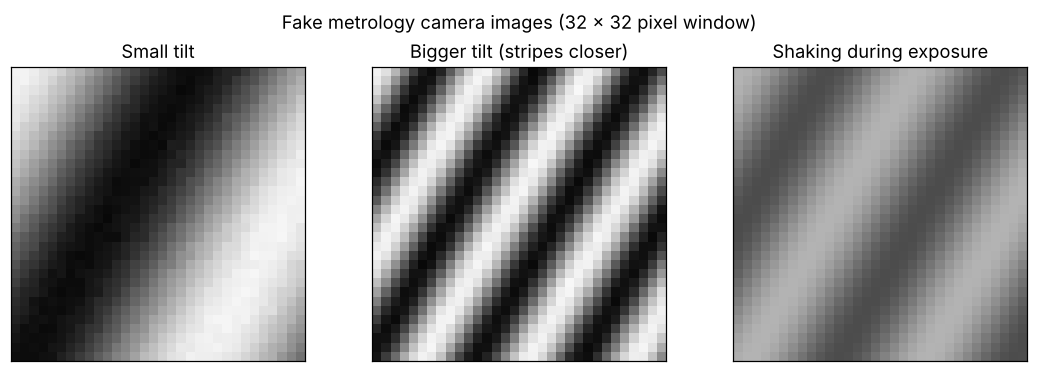

In [2]:
def make_fringe_image(roi=32, fringe_freq=0.06, angle_deg=30, opd_nm=0.0,
                      contrast=0.9, noise=0.02):
    '''Fake camera image of straight fringes.

    fringe_freq : stripes per pixel (more tilt -> bigger number)
    angle_deg   : direction of the stripes
    opd_nm      : mirror piston, shifts the stripes sideways
    contrast    : how sharp the stripes are (1 = perfect)
    noise       : camera noise
    '''
    y, x = np.mgrid[0:roi, 0:roi]                       # pixel coordinates
    k = 2 * np.pi * fringe_freq                         # stripes per pixel -> radians per pixel
    a = np.radians(angle_deg)
    phase = 2 * np.pi * opd_nm / WAVELENGTH_NM          # piston -> phase shift
    img = 1 + contrast * np.cos(k * (np.cos(a) * x + np.sin(a) * y) + phase)
    return img + noise * rng.standard_normal(img.shape)


def shaken_exposure(jitter_rms_nm, n_sub=200, **kw):
    '''One camera exposure while the mirror shakes: average many shifted images.'''
    shifts = jitter_rms_nm * rng.standard_normal(n_sub)
    return np.mean([make_fringe_image(opd_nm=s, noise=0, **kw) for s in shifts], axis=0)


fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
examples = [("Small tilt", make_fringe_image(fringe_freq=0.03)),
            ("Bigger tilt (stripes closer)", make_fringe_image(fringe_freq=0.10)),
            ("Shaking during exposure", shaken_exposure(300, fringe_freq=0.06))]
for ax, (title, img) in zip(axes, examples):
    ax.imshow(img, cmap="gray", vmin=0, vmax=2)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Fake metrology camera images (32 x 32 pixel window)")
plt.tight_layout(); plt.show()

## Part 2: How much does the mirror wobble? (RMS)

We record the mirror position (OPD) 1000 times a second. Even when the mirror should be still, it jiggles.
**RMS is the typical size of that jiggle.**

**Error bar:** cut the time window into 10 blocks and measure the RMS of each.
If the blocks agree, the error is small. This is more honest than the textbook formula,
because vibration makes neighbouring samples similar (they are not independent).

The fake signal below mixes three things: a slow drift (0.5 Hz), a 50 Hz vibration, and random noise.

RMS over the full 10 s exposure: 15.1 +- 0.1 nm


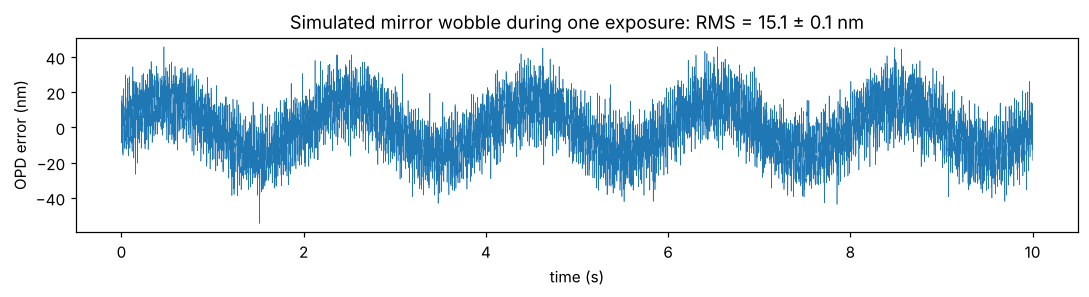

In [3]:
def rms_with_error(signal, fs_hz, window_s, n_blocks=10):
    '''RMS of the last `window_s` seconds of `signal`, with a block-method error bar.'''
    n = int(window_s * fs_hz)                    # samples in the window
    x = np.asarray(signal[-n:], dtype=float)
    rms = x.std()                                # typical size of the wobble
    blocks = np.array_split(x, n_blocks)         # 10 equal pieces
    block_rms = np.array([b.std() for b in blocks])
    err = block_rms.std(ddof=1) / np.sqrt(n_blocks)
    return rms, err


# 10 seconds of fake mirror position, sampled at the camera rate
t = np.arange(0, 10, 1 / CAMERA_FPS)
opd = (15 * np.sin(2 * np.pi * 0.5 * t)          # slow drift
       + 10 * np.sin(2 * np.pi * 50 * t)          # 50 Hz vibration
       + 8 * rng.standard_normal(t.size))         # random noise   (all in nm, made up)

rms, err = rms_with_error(opd, CAMERA_FPS, window_s=10)
print(f"RMS over the full 10 s exposure: {rms:.1f} +- {err:.1f} nm")

fig, ax = plt.subplots(figsize=(10, 2.8))
ax.plot(t, opd, lw=0.4, color="tab:blue")
ax.set_xlabel("time (s)"); ax.set_ylabel("OPD error (nm)")
ax.set_title(f"Simulated mirror wobble during one exposure: RMS = {rms:.1f} ± {err:.1f} nm")
plt.tight_layout(); plt.show()

### Why the time window matters

If we only watch for a short time, we miss the slow drift and the mirror *looks* calmer than it is.
The RMS only settles once the window covers a few cycles of the slowest wobble.
That's why the RMS for the science case should use the **full exposure (5 to 10 s)**.

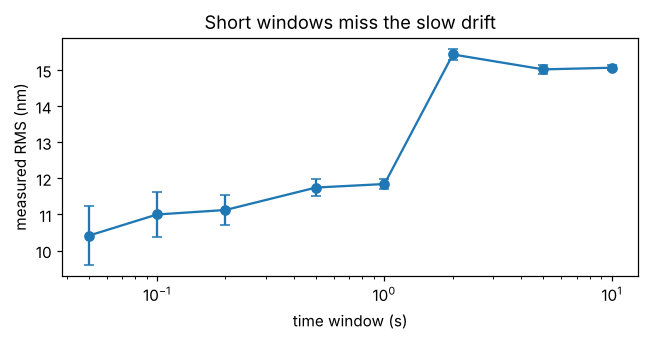

In [4]:
windows = np.array([0.05, 0.1, 0.2, 0.5, 1, 2, 5, 10])   # seconds
results = np.array([rms_with_error(opd, CAMERA_FPS, w) for w in windows])

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.errorbar(windows, results[:, 0], yerr=results[:, 1], marker="o", capsize=3)
ax.set_xscale("log")
ax.set_xlabel("time window (s)"); ax.set_ylabel("measured RMS (nm)")
ax.set_title("Short windows miss the slow drift")
plt.tight_layout(); plt.show()

## Part 3: How sharp are the fringes? (modulation efficiency)

We fit a perfect stripe pattern to the image:

$$I(x,y) = \text{mean} + \text{amp}\cdot\cos(k_x x + k_y y + \text{phase})$$

$$\text{Modulation efficiency} = \frac{\text{amp}}{\text{mean}} \quad (1 = \text{perfect stripes},\ 0 = \text{no stripes})$$

The fit also tells us how uncertain each number is, which gives the error bar.
The FFT gives the fit a good starting guess (it finds the strongest stripe pattern in the image).

Modulation efficiency: 0.861 +- 0.003   (true value 0.86)
Stripe frequency     : 0.0600 +- 0.0000 stripes/pixel (true 0.06)


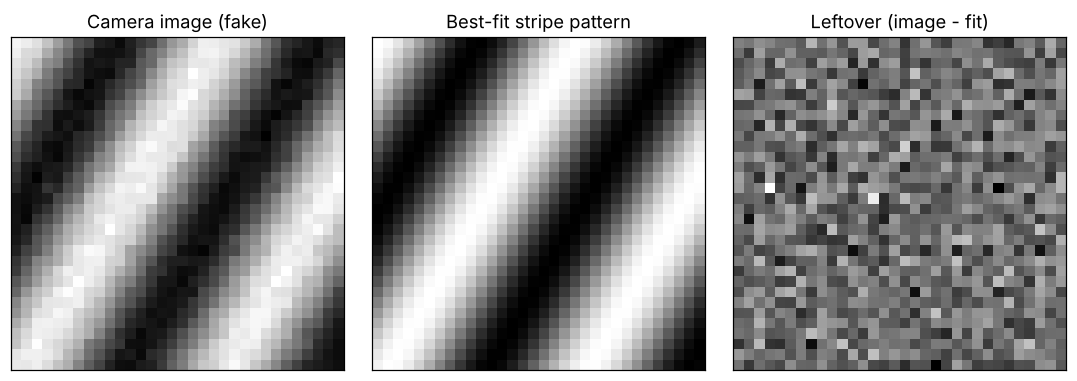

In [5]:
def _fringe_model(xy, mean, amp, kx, ky, phase):
    x, y = xy
    return mean + amp * np.cos(kx * x + ky * y + phase)


def fit_fringes(image):
    '''Fit straight fringes; return modulation efficiency and stripe frequency, with errors.'''
    img = np.asarray(image, dtype=float)
    ny, nx = img.shape
    y, x = np.mgrid[0:ny, 0:nx]

    # Starting guess from the brightest peak of the 2D FFT
    F = np.fft.fft2(img - img.mean()); F[0, 0] = 0
    iy, ix = np.unravel_index(np.argmax(np.abs(F)), F.shape)
    p0 = [img.mean(), (img.max() - img.min()) / 2,
          2 * np.pi * np.fft.fftfreq(nx)[ix], 2 * np.pi * np.fft.fftfreq(ny)[iy], 0.0]

    popt, pcov = curve_fit(_fringe_model, (x.ravel(), y.ravel()), img.ravel(), p0=p0)
    mean, amp, kx, ky, _ = popt
    perr = np.sqrt(np.diag(pcov))                 # 1-sigma errors from the fit
    amp = abs(amp)

    me = amp / mean
    me_err = me * np.hypot(perr[1] / amp, perr[0] / mean)
    k = np.hypot(kx, ky)
    k_err = np.hypot(kx * perr[2], ky * perr[3]) / k
    return dict(mod_eff=me, mod_eff_err=me_err,
                fringe_freq=k / (2 * np.pi), fringe_freq_err=k_err / (2 * np.pi),
                fit=_fringe_model((x, y), *popt))


img = make_fringe_image(contrast=MOD_EFF_NOW, noise=0.05)    # fake image with 86% contrast
res = fit_fringes(img)
print(f"Modulation efficiency: {res['mod_eff']:.3f} +- {res['mod_eff_err']:.3f}   (true value {MOD_EFF_NOW})")
print(f"Stripe frequency     : {res['fringe_freq']:.4f} +- {res['fringe_freq_err']:.4f} stripes/pixel (true 0.06)")

fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
for ax, (title, im) in zip(axes, [("Camera image (fake)", img),
                                   ("Best-fit stripe pattern", res["fit"]),
                                   ("Leftover (image - fit)", img - res["fit"])]):
    ax.imshow(im, cmap="gray"); ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

Over many frames, the **average** gives the best value, and the **frame-to-frame scatter**
is itself a stability measure: a steady mirror gives the same answer every frame.

In [6]:
def frames_summary(frames):
    '''Fit every frame: mean +- error of the mean, plus frame-to-frame scatter.'''
    fits = [fit_fringes(f) for f in frames]
    out = {}
    for key in ("mod_eff", "fringe_freq"):
        v = np.array([f[key] for f in fits])
        out[key] = v.mean()
        out[key + "_err"] = v.std(ddof=1) / np.sqrt(len(v))
        out[key + "_scatter"] = v.std(ddof=1)
    return out


frames = [make_fringe_image(contrast=MOD_EFF_NOW, opd_nm=o, noise=0.05)
          for o in 30 * rng.standard_normal(100)]               # 100 frames, mirror wobbling
s = frames_summary(frames)
print(f"Modulation efficiency over 100 frames: {s['mod_eff']:.4f} +- {s['mod_eff_err']:.4f} "
      f"(scatter {s['mod_eff_scatter']:.4f})")

Modulation efficiency over 100 frames: 0.8601 +- 0.0003 (scatter 0.0027)


## Part 4: Shaking washes out the fringes

If the mirror shakes **during** one exposure, the stripes slide back and forth and smear.
For random shaking with RMS $\sigma$, the contrast left is:

$$\text{ME}_\text{vib} = \exp\left[-\tfrac{1}{2}\left(\frac{2\pi\,\sigma_\text{OPD}}{\lambda}\right)^2\right]$$

Below: simulate shaken exposures, measure the contrast with the fit, and compare with the formula.
The second curve shows that **the same shaking hurts shorter wavelengths more**
(650 nm is just an example of visible light).

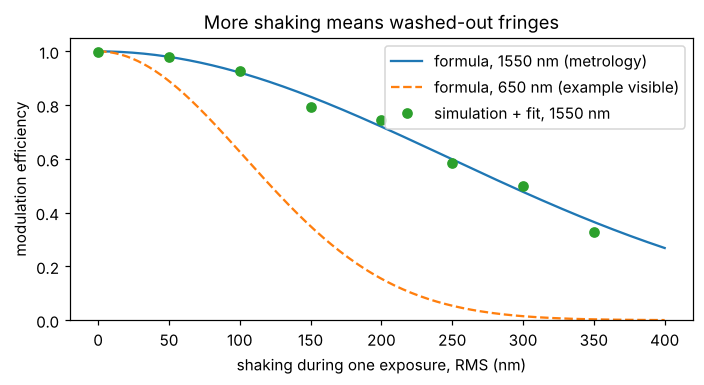

In [7]:
def predicted_mod_eff_vibration(opd_rms_nm, wavelength_nm=WAVELENGTH_NM):
    return np.exp(-0.5 * (2 * np.pi * opd_rms_nm / wavelength_nm) ** 2)


jitters = np.array([0, 50, 100, 150, 200, 250, 300, 350])        # nm RMS
measured = [fit_fringes(shaken_exposure(j, contrast=1.0) + 0.01 * rng.standard_normal((32, 32)))["mod_eff"]
            for j in jitters]

curve = np.linspace(0, 400, 200)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(curve, predicted_mod_eff_vibration(curve), label="formula, 1550 nm (metrology)")
ax.plot(curve, predicted_mod_eff_vibration(curve, 650), "--", label="formula, 650 nm (example visible)")
ax.plot(jitters, measured, "o", label="simulation + fit, 1550 nm")
ax.set_xlabel("shaking during one exposure, RMS (nm)"); ax.set_ylabel("modulation efficiency")
ax.set_title("More shaking means washed-out fringes"); ax.legend(); ax.set_ylim(0, 1.05)
plt.tight_layout(); plt.show()

**Notes from last meeting (Part 4)**
- add a line for 350 nm, the smallest wavelength. If the wavelength is shorter it should be better for correcting small variations.
- actively correcting for vibration in the system, at a rate of 1000 images per second; hundreds of nm/s → correct or you lose the mod eff
- have a simulation on the rate of correcting for the 1000 images of the system

### Follow-up: 350 nm, and how much jitter each wavelength can take

Turning the formula around gives the largest jitter that still keeps a chosen contrast:

$$\sigma_\text{max} = \frac{\lambda}{2\pi}\sqrt{-2\ln \text{ME}_\text{target}}$$

The target of 0.95 (keep 95% of the contrast) is an **example**; it is easy to change.

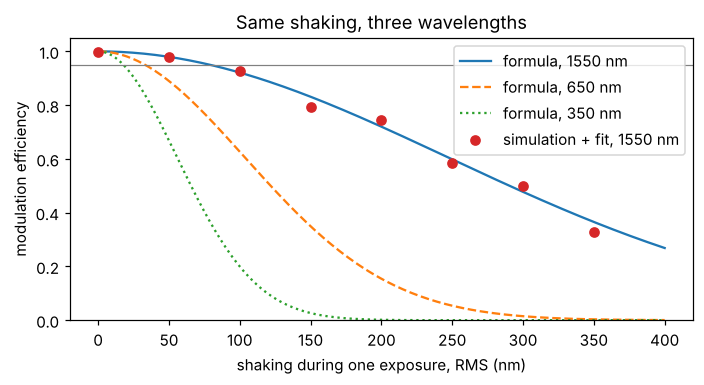

 1550 nm: OPD jitter must stay below  79.0 nm RMS for ME >= 0.95
  650 nm: OPD jitter must stay below  33.1 nm RMS for ME >= 0.95
  350 nm: OPD jitter must stay below  17.8 nm RMS for ME >= 0.95


In [8]:
WAVELENGTHS_NM = [1550, 650, 350]   # metrology, example visible, shortest science wavelength
ME_TARGET = 0.95                     # EXAMPLE requirement: keep 95% of the contrast

def max_jitter_nm(me_target, wavelength_nm):
    '''Turn the Part 4 formula around: largest OPD jitter (RMS) that still gives me_target.'''
    return wavelength_nm / (2 * np.pi) * np.sqrt(-2 * np.log(me_target))

fig, ax = plt.subplots(figsize=(6.5, 3.6))
for wl, style in zip(WAVELENGTHS_NM, ["-", "--", ":"]):
    ax.plot(curve, predicted_mod_eff_vibration(curve, wl), style, label=f"formula, {wl} nm")
ax.plot(jitters, measured, "o", label="simulation + fit, 1550 nm")
ax.axhline(ME_TARGET, color="gray", lw=0.8)
ax.set_xlabel("shaking during one exposure, RMS (nm)"); ax.set_ylabel("modulation efficiency")
ax.set_title("Same shaking, three wavelengths"); ax.legend(); ax.set_ylim(0, 1.05)
plt.tight_layout(); plt.show()

for wl in WAVELENGTHS_NM:
    print(f"{wl:5d} nm: OPD jitter must stay below {max_jitter_nm(ME_TARGET, wl):5.1f} nm RMS for ME >= {ME_TARGET}")

## Part 4b: Correcting the shaking actively, at the camera rate

The mirror drifts by **hundreds of nm per second**. Over a 10 s exposure that is microns of OPD,
which would wash the fringes out completely. So the piezos must correct it while we expose.

The loop below, for each camera frame:
1. the camera measures the OPD error, **averaged over the frame**, plus a little noise,
2. the result arrives **one frame late** (readout and processing),
3. the piezo moves by `gain × measurement` and holds there until the next update.

The "real" mirror motion is simulated on a much finer time grid, so we can see what happens *between* frames.
The contrast is computed directly as the average of $e^{i\,2\pi\,\text{OPD}/\lambda}$ over the exposure
(the same trick as the simulation in Part 5). This is exact for any shape of motion, not only random noise.

**The disturbance is made up:** 300 nm/s drift + slow 0.5 Hz wander + 50 Hz vibration.

In [9]:
SIM_RATE_HZ = 12000        # fine time grid for the "real" mirror motion

def disturbance_nm(t):
    '''Made-up OPD disturbance: 300 nm/s drift + 0.5 Hz wander + 50 Hz vibration.'''
    return 300 * t + 15 * np.sin(2 * np.pi * 0.5 * t) + 10 * np.sin(2 * np.pi * 50 * t)


def run_loop(d, loop_hz, gain=0.5, noise_nm=3.0, delay_frames=1):
    '''Piezo correction updated loop_hz times a second. Returns the leftover OPD error.'''
    step = SIM_RATE_HZ // loop_hz                  # fine samples in one camera frame
    correction = np.zeros_like(d)
    c, measurements = 0.0, []
    for k in range(len(d) // step):
        frame = slice(k * step, (k + 1) * step)
        correction[frame] = c                                           # piezo holds during the frame
        seen = np.mean(d[frame] - c) + noise_nm * rng.standard_normal()  # camera averages over the frame
        measurements.append(seen)
        if len(measurements) > delay_frames:                           # the result arrives late
            c += gain * measurements[-1 - delay_frames]
    return d - correction


def mod_eff_from_opd(opd_nm, wavelength_nm):
    '''Contrast left after averaging fringes over a wandering OPD (exact, any shape of motion).'''
    return np.abs(np.mean(np.exp(2j * np.pi * opd_nm / wavelength_nm)))


t_fine = np.arange(0, 11, 1 / SIM_RATE_HZ)      # 1 s for the loop to lock, then a 10 s exposure
d = disturbance_nm(t_fine)
expo = slice(SIM_RATE_HZ, None)                 # the exposure part

print("No correction, over the 10 s exposure:")
for wl in WAVELENGTHS_NM:
    print(f"   {wl:5d} nm: ME = {mod_eff_from_opd(d[expo], wl):.2f}")

No correction, over the 10 s exposure:
    1550 nm: ME = 0.03
     650 nm: ME = 0.01
     350 nm: ME = 0.04


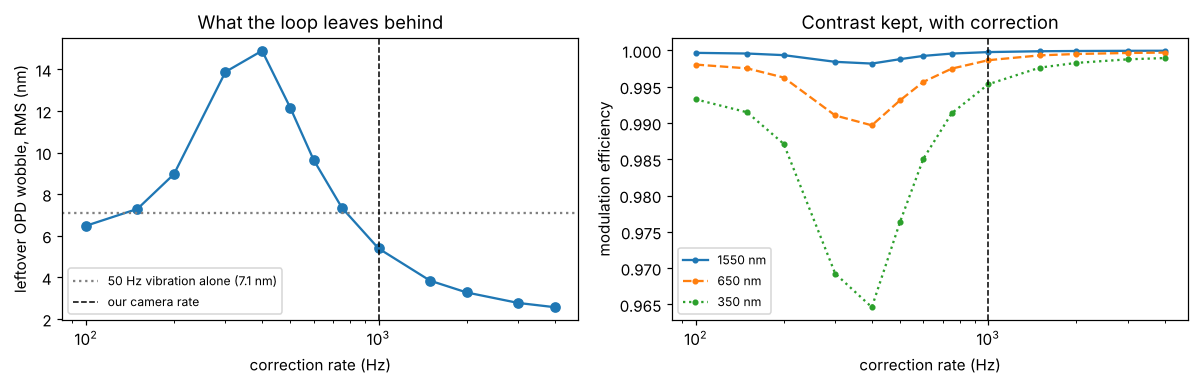

At 1000 Hz: leftover wobble 5.4 nm RMS -> ME = 1.000 (1550 nm), 0.999 (650 nm), 0.995 (350 nm)


In [10]:
loop_rates = np.array([100, 150, 200, 300, 400, 500, 600, 750, 1000, 1500, 2000, 3000, 4000])
leftover = [run_loop(d, f)[expo] for f in loop_rates]
leftover_rms = np.array([r.std() for r in leftover])
vib_alone = (10 * np.sin(2 * np.pi * 50 * t_fine[expo])).std()   # the 50 Hz line on its own

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
ax.plot(loop_rates, leftover_rms, "o-")
ax.axhline(vib_alone, color="gray", ls=":", label=f"50 Hz vibration alone ({vib_alone:.1f} nm)")
ax.axvline(CAMERA_FPS, color="k", ls="--", lw=1, label="our camera rate")
ax.set_xscale("log"); ax.set_xlabel("correction rate (Hz)"); ax.set_ylabel("leftover OPD wobble, RMS (nm)")
ax.set_title("What the loop leaves behind"); ax.legend(fontsize=8)

ax = axes[1]
for wl, style in zip(WAVELENGTHS_NM, ["-", "--", ":"]):
    ax.plot(loop_rates, [mod_eff_from_opd(r, wl) for r in leftover], "o" + style, ms=3, label=f"{wl} nm")
ax.axvline(CAMERA_FPS, color="k", ls="--", lw=1)
ax.set_xscale("log"); ax.set_xlabel("correction rate (Hz)"); ax.set_ylabel("modulation efficiency")
ax.set_title("Contrast kept, with correction"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

i = list(loop_rates).index(CAMERA_FPS)
print(f"At {CAMERA_FPS} Hz: leftover wobble {leftover_rms[i]:.1f} nm RMS -> ME = "
      + ", ".join(f"{mod_eff_from_opd(leftover[i], wl):.3f} ({wl} nm)" for wl in WAVELENGTHS_NM))

**What this shows**
- Without correction the drift alone destroys the fringes over a 10 s exposure, at every wavelength.
- **Any** loop rate here removes the drift easily. Drift is slow, so it is the easy part.
- The **50 Hz vibration** is the hard part. A loop that is only a few times faster than the vibration
  (here about 150–750 Hz) reacts too late and actually makes the 50 Hz worse (points above the dotted line).
  The loop needs to run roughly **15–20× faster than the vibration** to beat it down. At 1000 Hz it does.
- Gain, delay and noise are made up, so the exact crossover will move on the real bench. The method stays the same.
- About the shorter wavelength: the *science* light at 350 nm is hurt most by the same leftover wobble.
  A shorter *metrology* wavelength would measure small motions more finely, though
  (phase noise $\sigma_\phi$ becomes $\sigma_\phi\lambda/2\pi$ in nm).

## Part 5: Tilt washes out the fringes (for a detector that sums the whole beam)

On the metrology camera, tilt makes stripes *across* the image.
But a detector pixel that **adds up the whole beam** (like the science detector) sees all those
stripes at once, and they cancel each other out. For a round beam of radius $R$ and mirror tilt $\alpha$:

$$\text{ME}_\text{tilt} = \left|\frac{2J_1(u)}{u}\right|, \qquad u = \frac{4\pi\,\alpha R}{\lambda}$$

(The 4π instead of 2π is because reflection doubles the tilt.)
Below: a brute-force simulation over a round beam, compared with the formula.
**The beam radius is an example value: change it to ours.**

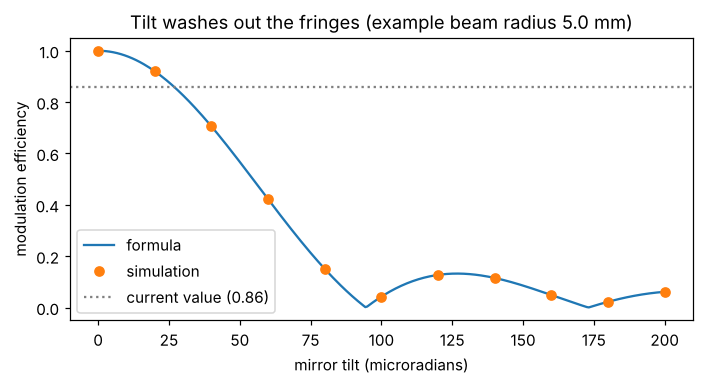

In [11]:
BEAM_RADIUS_MM = 5.0        # EXAMPLE value, to replace with the real beam size

def predicted_mod_eff_tilt(tilt_urad, radius_mm=BEAM_RADIUS_MM, wavelength_nm=WAVELENGTH_NM):
    u = 4 * np.pi * (tilt_urad * 1e-6) * (radius_mm * 1e-3) / (wavelength_nm * 1e-9)
    u = np.where(u == 0, 1e-12, u)
    return np.abs(2 * j1(u) / u)

def simulated_mod_eff_tilt(tilt_urad, radius_mm=BEAM_RADIUS_MM, n=301):
    '''Average the light over a round beam with a tilted wavefront.'''
    x = np.linspace(-1, 1, n) * radius_mm * 1e-3
    X, Y = np.meshgrid(x, x)
    inside = X**2 + Y**2 <= (radius_mm * 1e-3) ** 2
    phase = 2 * np.pi * (2 * tilt_urad * 1e-6 * X) / (WAVELENGTH_NM * 1e-9)
    return np.abs(np.exp(1j * phase[inside]).mean())

tilts = np.linspace(0, 200, 300)
sim_tilts = np.arange(0, 201, 20)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(tilts, predicted_mod_eff_tilt(tilts), label="formula")
ax.plot(sim_tilts, [simulated_mod_eff_tilt(a) for a in sim_tilts], "o", label="simulation")
ax.axhline(MOD_EFF_NOW, color="gray", ls=":", label=f"current value ({MOD_EFF_NOW})")
ax.set_xlabel("mirror tilt (microradians)"); ax.set_ylabel("modulation efficiency")
ax.set_title(f"Tilt washes out the fringes (example beam radius {BEAM_RADIUS_MM} mm)")
ax.legend(); plt.tight_layout(); plt.show()

**Note from last meeting (Part 5):** the beam is relatively larger, about 1 inch.

### Follow-up: 1-inch beam, and how much tilt each wavelength can take

I assumed **1 inch is the beam diameter**, so the radius is 12.7 mm (to confirm).
A bigger beam is *more* sensitive to tilt: the same angle puts more OPD across the beam.

Python detail: `predicted_mod_eff_tilt` got its default `radius_mm` when it was defined (5 mm),
so changing `BEAM_RADIUS_MM` now does **not** change that default. We pass the radius explicitly.

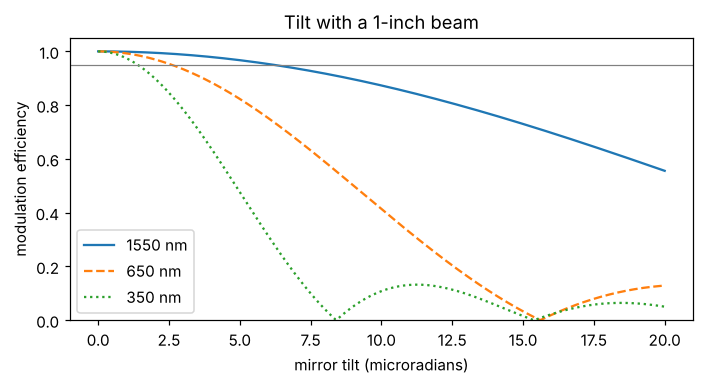

 1550 nm: tilt must stay below 6.19 urad for ME >= 0.95
  650 nm: tilt must stay below 2.60 urad for ME >= 0.95
  350 nm: tilt must stay below 1.40 urad for ME >= 0.95


In [12]:
from scipy.optimize import brentq

BEAM_RADIUS_MM = 12.7       # 1 inch DIAMETER (meeting) -> 12.7 mm radius. To confirm.

def max_tilt_urad(me_target, radius_mm, wavelength_nm):
    '''Largest mirror tilt that still gives me_target (solve formula = target).'''
    f = lambda a: float(predicted_mod_eff_tilt(a, radius_mm, wavelength_nm)) - me_target
    return brentq(f, 1e-6, 50)          # search between ~0 and 50 microradians

tilts = np.linspace(0, 20, 400)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for wl, style in zip(WAVELENGTHS_NM, ["-", "--", ":"]):
    ax.plot(tilts, predicted_mod_eff_tilt(tilts, BEAM_RADIUS_MM, wl), style, label=f"{wl} nm")
ax.axhline(ME_TARGET, color="gray", lw=0.8)
ax.set_xlabel("mirror tilt (microradians)"); ax.set_ylabel("modulation efficiency")
ax.set_title("Tilt with a 1-inch beam"); ax.legend(); ax.set_ylim(0, 1.05)
plt.tight_layout(); plt.show()

for wl in WAVELENGTHS_NM:
    print(f"{wl:5d} nm: tilt must stay below {max_tilt_urad(ME_TARGET, BEAM_RADIUS_MM, wl):.2f} urad for ME >= {ME_TARGET}")

## Part 6: How tilted is the mirror?

More tilt means stripes packed closer together. Reflection doubles the angle, so one stripe
across a distance $d$ on the mirror means tilt $= \lambda / (2d)$.

To go from "stripes per pixel" to a real angle we need the **pixel scale** (how much mirror one pixel covers).
That number is still to be measured, so the value below is a **placeholder**.

Note: on the metrology camera some stripes are there on purpose (in Servo's setup the laser comes in at an angle),
so the useful number is how much the tilt **changes** from frame to frame. A steady mirror gives a small scatter.

In [13]:
PIXEL_SCALE_UM = 30.0       # PLACEHOLDER: size of one camera pixel on the mirror, to be measured

def tilt_from_fringes(fringe_freq, fringe_freq_err, pixel_scale_um=PIXEL_SCALE_UM,
                      wavelength_nm=WAVELENGTH_NM):
    period_um = pixel_scale_um / fringe_freq                  # stripe spacing on the mirror
    tilt_urad = wavelength_nm * 1e-3 / (2 * period_um) * 1e6  # the 2: reflection doubles the angle
    return tilt_urad, tilt_urad * fringe_freq_err / fringe_freq

tilt, tilt_err = tilt_from_fringes(s["fringe_freq"], s["fringe_freq_err"])
tilt_scatter, _ = tilt_from_fringes(s["fringe_freq_scatter"], 0)   # same conversion for the scatter
print(f"Tilt (includes the deliberate stripes): {tilt:.1f} +- {tilt_err:.2f} microradians")
print(f"Tilt stability, frame-to-frame scatter : {tilt_scatter:.3f} microradians")
print("(both use the placeholder pixel scale)")

Tilt (includes the deliberate stripes): 1550.3 +- 0.10 microradians
Tilt stability, frame-to-frame scatter : 1.016 microradians
(both use the placeholder pixel scale)


**Notes from last meeting (Part 6)**
- we might not be able to feed in the perfect number; we might have to compute it after moving the piezo actively
- use 15 microns for the camera pixel scale
- to need 6 microns you have to be very misaligned (probably need much less, like half a fringe)
- track from 0 OPD (max flux), move, decide on the right fringes and keep tracking the position

### Follow-up: 15 µm pixel scale

Same function, with the meeting value passed in explicitly (same default-argument issue as Part 5).
The frame-to-frame scatter is then compared with the tilt allowed at 350 nm from Part 5.

In [14]:
PIXEL_SCALE_UM = 15.0       # from the meeting

tilt, tilt_err = tilt_from_fringes(s["fringe_freq"], s["fringe_freq_err"], pixel_scale_um=PIXEL_SCALE_UM)
tilt_scatter, _ = tilt_from_fringes(s["fringe_freq_scatter"], 0, pixel_scale_um=PIXEL_SCALE_UM)
allowed_350 = max_tilt_urad(ME_TARGET, BEAM_RADIUS_MM, 350)

print(f"Tilt (includes the deliberate stripes): {tilt:.0f} +- {tilt_err:.1f} microradians")
print(f"Tilt stability, frame-to-frame scatter : {tilt_scatter:.2f} microradians")
print(f"Tilt allowed at 350 nm (Part 5)        : {allowed_350:.2f} microradians")

Tilt (includes the deliberate stripes): 3101 +- 0.2 microradians
Tilt stability, frame-to-frame scatter : 2.03 microradians
Tilt allowed at 350 nm (Part 5)        : 1.40 microradians


Here the mirror in the fake frames never tilts, so the scatter is **only measurement noise**:
with this noise level, one 32 × 32 frame measures tilt to about the same size as the 350 nm requirement.
To check that requirement on the bench we would need a bigger window, a less noisy camera, or averaging over frames.

## Part 6b: Measuring the pixel scale by moving the piezo

Instead of trusting a number, command a few known tilts with the piezos and watch the stripes change.
Stripe frequency grows in a straight line with tilt:

$$f = f_0 + \frac{2\,p}{\lambda}\,\alpha \qquad (p = \text{pixel scale},\ \alpha = \text{tilt})$$

so the **slope** of a straight-line fit gives $p = \text{slope}\cdot\lambda/2$.
The deliberate stripes only change $f_0$, so they don't matter here.

To know the commanded tilt we need the piezo geometry (difference in piezo extension ÷ distance between piezos).
Below, the "true" pixel scale is hidden inside the fake images, and the fit has to find it.

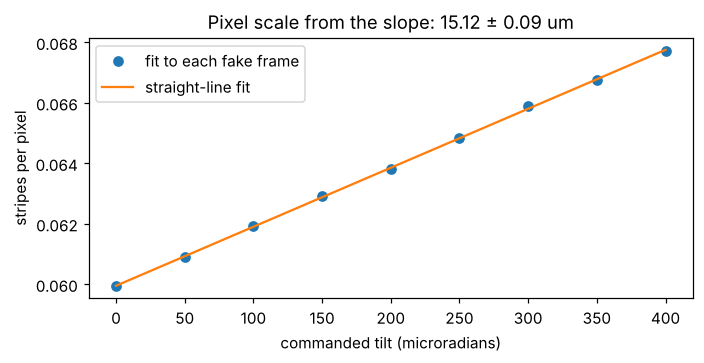

Recovered pixel scale: 15.12 +- 0.09 um   (true 15.0)


In [15]:
TRUE_PIXEL_SCALE_UM = 15.0                       # hidden inside the fake images
commanded_tilt_urad = np.arange(0, 401, 50)       # tilts we command with the piezos

def fringe_freq_for_tilt(tilt_urad, pixel_scale_um, f0=0.06):
    '''Stripes per pixel for a given extra tilt (f0 = the deliberate stripes).'''
    return f0 + 2 * (tilt_urad * 1e-6) * (pixel_scale_um * 1e-6) / (WAVELENGTH_NM * 1e-9)

measured_freq = []
for a in commanded_tilt_urad:
    img = make_fringe_image(fringe_freq=fringe_freq_for_tilt(a, TRUE_PIXEL_SCALE_UM),
                            angle_deg=0, contrast=MOD_EFF_NOW, noise=0.05)
    measured_freq.append(fit_fringes(img)["fringe_freq"])
measured_freq = np.array(measured_freq)

tilt_rad = commanded_tilt_urad * 1e-6
(slope, f0), cov = np.polyfit(tilt_rad, measured_freq, 1, cov=True)   # straight-line fit
slope_err = np.sqrt(cov[0, 0])
pixel_scale_um = slope * WAVELENGTH_NM * 1e-9 / 2 * 1e6
pixel_scale_err = slope_err * WAVELENGTH_NM * 1e-9 / 2 * 1e6

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(commanded_tilt_urad, measured_freq, "o", label="fit to each fake frame")
ax.plot(commanded_tilt_urad, f0 + slope * tilt_rad, "-", label="straight-line fit")
ax.set_xlabel("commanded tilt (microradians)"); ax.set_ylabel("stripes per pixel")
ax.set_title(f"Pixel scale from the slope: {pixel_scale_um:.2f} ± {pixel_scale_err:.2f} um"); ax.legend()
plt.tight_layout(); plt.show()
print(f"Recovered pixel scale: {pixel_scale_um:.2f} +- {pixel_scale_err:.2f} um   (true {TRUE_PIXEL_SCALE_UM})")

## Part 6c: Tracking the fringes from zero OPD

The camera only sees the fringe phase **modulo one fringe**: it cannot tell OPD = 0.3 fringes from 1.3 fringes.
So we start at **zero OPD** (where the white-light flux is highest), then follow the phase frame by frame
and count whole fringes as they go by (`np.unwrap`).

This only works if the OPD changes by **less than half a fringe between two frames**.
Otherwise the code can't tell whether the stripes moved forward or backward, and it loses count.
The speed limit is

$$v_\text{max} = \frac{\lambda}{2}\times \text{frame rate}$$

in OPD (the mirror itself moves half as fast).

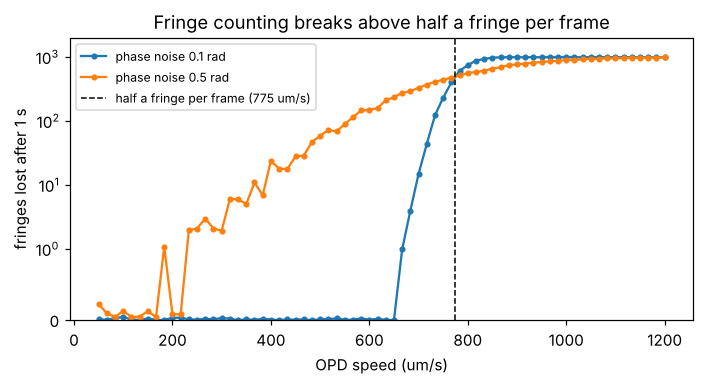

Speed limit at 1550 nm and 1000 fps: 775 um/s OPD = 388 um/s of mirror motion (less with more noise)
Actuator landing error 0.2 um of mirror = 0.26 fringe of OPD -> less than half a fringe


In [16]:
def track_opd(speed_um_s, duration_s=1.0, phase_noise_rad=0.1,
              wavelength_nm=WAVELENGTH_NM, fps=CAMERA_FPS):
    '''Start at zero OPD, move at constant speed, count fringes. Returns the counting error in fringes.'''
    t = np.arange(0, duration_s, 1 / fps)
    true_opd = speed_um_s * 1e3 * t                                              # nm
    phase = 2 * np.pi * true_opd / wavelength_nm + phase_noise_rad * rng.standard_normal(t.size)
    wrapped = np.angle(np.exp(1j * phase))                   # what the camera sees: phase between -pi and pi
    tracked_opd = np.unwrap(wrapped) * wavelength_nm / (2 * np.pi)
    return (tracked_opd[-1] - true_opd[-1]) / wavelength_nm

v_max = WAVELENGTH_NM / 2 * CAMERA_FPS / 1e3                 # um/s of OPD
speeds = np.linspace(50, 1200, 70)

fig, ax = plt.subplots(figsize=(6.5, 3.6))
for noise in [0.1, 0.5]:
    ax.plot(speeds, [abs(track_opd(v, phase_noise_rad=noise)) for v in speeds], "o-", ms=3,
            label=f"phase noise {noise} rad")
ax.axvline(v_max, color="k", ls="--", lw=1, label=f"half a fringe per frame ({v_max:.0f} um/s)")
ax.set_yscale("symlog", linthresh=1); ax.set_ylim(0, 2000)
ax.set_xlabel("OPD speed (um/s)"); ax.set_ylabel("fringes lost after 1 s")
ax.set_title("Fringe counting breaks above half a fringe per frame"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"Speed limit at {WAVELENGTH_NM:.0f} nm and {CAMERA_FPS} fps: {v_max:.0f} um/s OPD "
      f"= {v_max/2:.0f} um/s of mirror motion (less with more noise)")
print(f"Actuator landing error {ACTUATOR_ERR_UM} um of mirror = {2*ACTUATOR_ERR_UM/(WAVELENGTH_NM*1e-3):.2f} fringe of OPD "
      f"-> less than half a fringe")

**What this means**
- Fast actuator moves (above ~0.4 mm/s of mirror motion) would lose the fringe count.
  **Noise lowers the limit a lot:** with 0.5 rad of phase noise, counting already fails around 200 µm/s.
  Two ways around it: move slower, or feed the actuator's *commanded* position into the tracker
  so it only has to follow the small difference.
- The actuator lands within 0.2 µm, which is about a quarter of a fringe in OPD.
  That's less than half a fringe, so the piezo only ever needs to correct a fraction of one fringe after a move.
  This matches the meeting note: we need much less than the full 6 µm.

## Part 7: Do the piezos have enough room?

From the meeting: the piezos travel **12 µm** and start halfway (**6 µm**), so there are 6 µm of room each way.
The actuator lands within **0.2 µm**, so the settle step only needs a tiny part of that range.
we expect we'll never use more than about **10%** of the travel.

 keep a margin at each end (here 20%) so the piezos never hit their limits.

Safe range: 2.4 to 9.6 um  (start at 6.0 um)
Settle gap (0.2 um) uses 3% of the room on one side


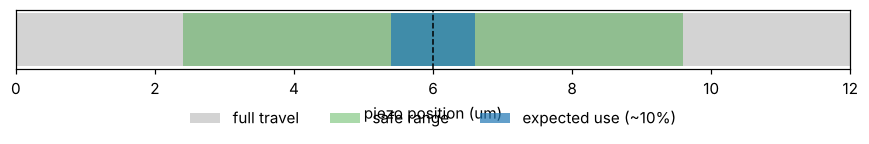

In [17]:
def piezo_safe_range(travel_um=PIEZO_TRAVEL_UM, margin_frac=0.2):
    lo, hi = margin_frac * travel_um, (1 - margin_frac) * travel_um
    return dict(lo=lo, hi=hi)

def piezo_ok(position_um, safe):
    '''If outside the safe range, the actuator should take over and the piezo re-centres.'''
    return safe["lo"] <= position_um <= safe["hi"]

safe = piezo_safe_range()
print(f"Safe range: {safe['lo']:.1f} to {safe['hi']:.1f} um  (start at {PIEZO_START_UM} um)")
print(f"Settle gap ({ACTUATOR_ERR_UM} um) uses {ACTUATOR_ERR_UM / (PIEZO_TRAVEL_UM/2):.0%} of the room on one side")

fig, ax = plt.subplots(figsize=(8, 1.8))
ax.barh(0, PIEZO_TRAVEL_UM, color="lightgray", label="full travel")
ax.barh(0, safe["hi"] - safe["lo"], left=safe["lo"], color="tab:green", alpha=0.4, label="safe range")
ax.barh(0, 0.1 * PIEZO_TRAVEL_UM, left=PIEZO_START_UM - 0.05 * PIEZO_TRAVEL_UM,
        color="tab:blue", alpha=0.7, label="expected use (~10%)")
ax.axvline(PIEZO_START_UM, color="k", ls="--", lw=1)
ax.set_yticks([]); ax.set_xlabel("piezo position (um)"); ax.set_xlim(0, PIEZO_TRAVEL_UM)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.45), ncol=3, frameon=False)
plt.tight_layout(); plt.show()

## Part 8: Simulating the settle step

After each actuator move, the mirror is up to 0.2 µm away from its target.
The piezos close that gap with a simple feedback loop, 1000 times a second:

```
error = target - measured position
piezo command += gain * error
```

The model includes small vibration, camera noise, and a piezo that doesn't react instantly.
A bigger gain settles faster, but too big starts to overshoot. **All numbers are made up for illustration.**

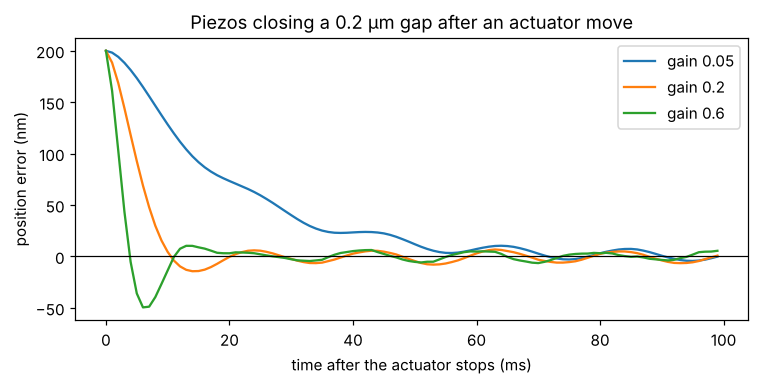

In [18]:
def simulate_settle(start_error_nm, gain, t_end=0.1, fs=CAMERA_FPS,
                    piezo_lag_s=0.003, vib_nm=5, meas_noise_nm=3, delay_frames=0):
    '''Return time and position error (nm) while the piezo closes the gap.'''
    n = int(t_end * fs); dt = 1 / fs
    command = 0.0                 # what we tell the piezo
    piezo = 0.0                   # where the piezo actually is (it lags behind)
    t = np.arange(n) * dt
    error = np.empty(n)
    seen = []                     # camera measurements, oldest first
    for i in range(n):
        true_err = start_error_nm - piezo + vib_nm * np.sin(2 * np.pi * 50 * t[i])
        measured = true_err + meas_noise_nm * rng.standard_normal()   # what the camera sees
        seen.append(measured)
        if len(seen) > delay_frames:                                  # result may arrive late
            command += gain * seen[-1 - delay_frames]                 # feedback: push toward target
        piezo += (command - piezo) * dt / piezo_lag_s                 # piezo catches up gradually
        error[i] = true_err
    return t, error

fig, ax = plt.subplots(figsize=(7, 3.6))
for gain in [0.05, 0.2, 0.6]:
    t_s, e = simulate_settle(200, gain)          # start 200 nm (0.2 um) away
    ax.plot(t_s * 1000, e, label=f"gain {gain}")
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("time after the actuator stops (ms)"); ax.set_ylabel("position error (nm)")
ax.set_title("Piezos closing a 0.2 µm gap after an actuator move"); ax.legend()
plt.tight_layout(); plt.show()

**Note from last meeting (Part 8):** the gain is likely to be bigger, with larger flux. SITELLE uses ~3.0.

### Follow-up: what a gain of 3 does in this model

I added one option to `simulate_settle`: `delay_frames`, for when the camera result reaches the piezo one frame late.
With `delay_frames=0` it behaves exactly as before.

delay 0 frame, gain 0.2: settles in 9 ms
delay 0 frame, gain 0.6: settles in 10 ms
delay 0 frame, gain 1.0: settles in 11 ms
delay 0 frame, gain 3.0: settles in 11 ms
delay 1 frame, gain 0.2: settles in 18 ms
delay 1 frame, gain 0.6: settles in 42 ms
delay 1 frame, gain 1.0: UNSTABLE / never settles
delay 1 frame, gain 3.0: UNSTABLE / never settles


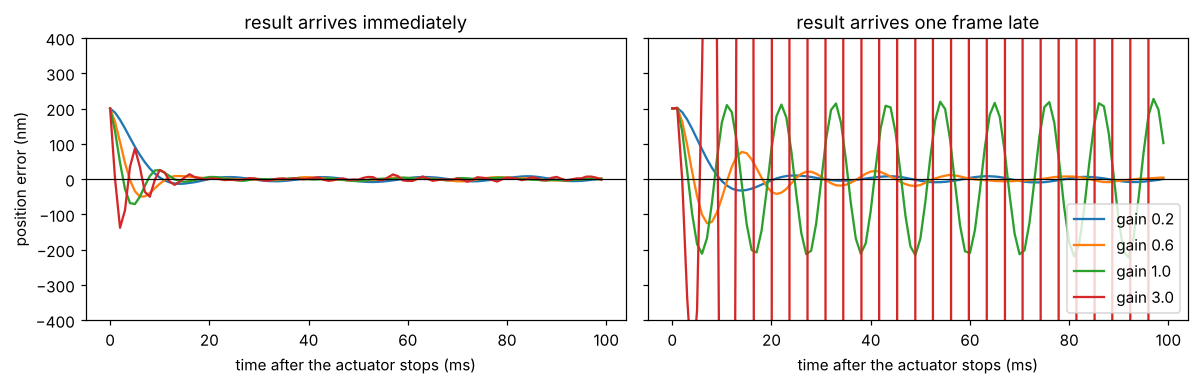

In [19]:
def settle_time_ms(t_s, e, tol_nm=20):
    '''Time after which the error stays within tol_nm. None if it never settles.'''
    outside = np.where(np.abs(e) > tol_nm)[0]
    if len(outside) == 0:
        return 0.0
    if outside[-1] >= len(e) - 5:          # still outside at the end -> never settled
        return None
    return t_s[outside[-1] + 1] * 1000

gains = [0.2, 0.6, 1.0, 3.0]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, delay in zip(axes, [0, 1]):
    for g in gains:
        t_s, e = simulate_settle(200, g, delay_frames=delay)
        ax.plot(t_s * 1000, e, label=f"gain {g}")
        ts = settle_time_ms(t_s, e)
        print(f"delay {delay} frame, gain {g}: " + ("UNSTABLE / never settles" if ts is None else f"settles in {ts:.0f} ms"))
    ax.axhline(0, color="k", lw=0.8); ax.set_ylim(-400, 400)
    ax.set_xlabel("time after the actuator stops (ms)")
    ax.set_title("result arrives immediately" if delay == 0 else "result arrives one frame late")
axes[0].set_ylabel("position error (nm)"); axes[1].legend()
plt.tight_layout(); plt.show()

**What this shows**
- With no delay, gain 3 still works but overshoots a lot. It isn't faster, because here the **piezo's own
  response time (3 ms, made up)** is what limits the speed, not the gain.
- With a one-frame delay, this loop becomes unstable around **gain 1**, so gain 3 runs away.
- So SITELLE's 3.0 is probably defined differently from my `gain` (for example per second, or with the delay already
  built in). **Question:** how is SITELLE's gain defined, and how long between a camera frame and the piezo moving?

### A full scan: 50 steps

Each step the actuator lands somewhere within ±0.2 µm, and the piezo takes up the difference.
Because the errors are random, the piezo wanders around its centre but stays well inside the safe range.
If it ever left the safe range, the code would let the actuator take over (offload) and re-centre the piezo.

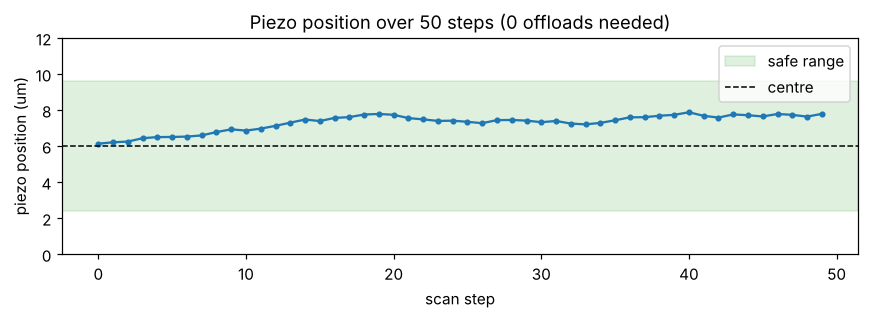

In [20]:
piezo_pos = PIEZO_START_UM
history, offloads = [], 0
for step in range(50):
    landing_error = rng.uniform(-ACTUATOR_ERR_UM, ACTUATOR_ERR_UM)   # where the actuator really stopped
    piezo_pos += landing_error                                        # piezo makes up the difference
    if not piezo_ok(piezo_pos, safe):                                 # too close to a limit?
        piezo_pos = PIEZO_START_UM                                    # offload to actuator, re-centre
        offloads += 1
    history.append(piezo_pos)

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(history, "o-", ms=3)
ax.axhspan(safe["lo"], safe["hi"], color="tab:green", alpha=0.15, label="safe range")
ax.axhline(PIEZO_START_UM, color="k", ls="--", lw=1, label="centre")
ax.set_xlabel("scan step"); ax.set_ylabel("piezo position (um)"); ax.set_ylim(0, PIEZO_TRAVEL_UM)
ax.set_title(f"Piezo position over 50 steps ({offloads} offloads needed)"); ax.legend()
plt.tight_layout(); plt.show()

## Part 9: Is there a tilt bias after each actuator move?

Question from the meeting: when the actuator moves step after step, does it tilt the mirror
**the same way every time**? If so, the code could correct it in advance instead of waiting to see it.

How to check: record the tilt after each step, then see whether the average is clearly different from zero.
Below is **fake data with a small bias built in**, to show the method. With real data from the actuator,
we run exactly the same test.

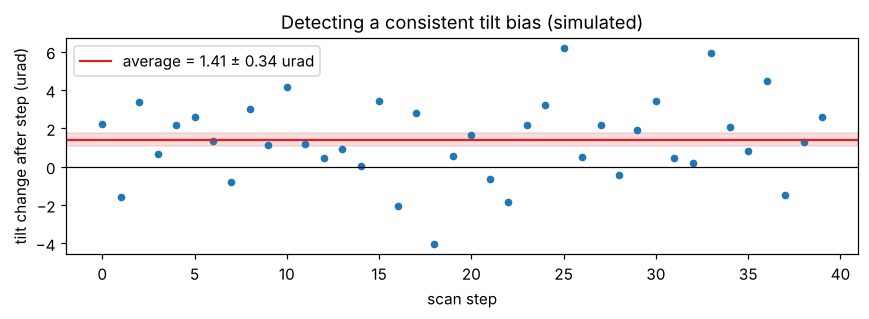

Average is 4.2 error bars away from zero: a real bias


In [21]:
n_steps = 40
true_bias = 1.5                                      # urad per step, FAKE
tilt_after_step = true_bias + 2.0 * rng.standard_normal(n_steps)   # bias + random scatter

mean = tilt_after_step.mean()
err = tilt_after_step.std(ddof=1) / np.sqrt(n_steps)  # error on the mean
significance = mean / err

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(tilt_after_step, "o", ms=4)
ax.axhline(0, color="k", lw=0.8)
ax.axhline(mean, color="tab:red", label=f"average = {mean:.2f} ± {err:.2f} urad")
ax.axhspan(mean - err, mean + err, color="tab:red", alpha=0.15)
ax.set_xlabel("scan step"); ax.set_ylabel("tilt change after step (urad)")
ax.set_title("Detecting a consistent tilt bias (simulated)"); ax.legend()
plt.tight_layout(); plt.show()

print(f"Average is {significance:.1f} error bars away from zero:",
      "a real bias" if abs(significance) > 3 else "no clear bias")

## Questions for today

From last meeting:
- Any modifications needed because of the rooftop mirrors?
- Was their code built for the metrology camera?
- Can we use Ziling's code for some of these simulations?

New:
1. Is the 1-inch beam the **diameter** (12.7 mm radius, as assumed) or the radius?
2. How is SITELLE's servo gain of ~3 defined, and what is the delay between a camera frame and the piezo moving?
3. Is ME ≥ 0.95 a sensible target, and is 350 nm the right worst case?
4. For the pixel-scale calibration (6b): what is the distance between the piezos, so a commanded extension becomes a known tilt?
5. How fast does the actuator move between steps? Above ~0.4 mm/s the fringe count is lost (6c).

## Summary

**From before**
- Stability as numbers: RMS, modulation efficiency and tilt, each with an error bar.
- The fit recovers the true contrast and stripe spacing on simulated frames.
- Shaking and tilt wash out the fringes as the formulas predict.
- Piezo room is not a problem; the settle step and the tilt-bias test are ready to try on the bench.

**New today**
- **Requirements per wavelength (ME ≥ 0.95, example target):** at 350 nm, OPD jitter below ~18 nm RMS and,
  with a 1-inch beam, tilt below ~1.4 µrad. 350 nm is the worst case for both.
- **Active correction:** uncorrected drift destroys the fringes over 10 s. A 1000 Hz loop keeps ME ≈ 0.99 even at 350 nm
  in this model. Drift is easy to correct; the 50 Hz vibration needs a loop ~15–20× faster than itself; slower loops make it worse.
- **Pixel scale** can be measured on the bench from the slope of fringe frequency vs commanded tilt (recovered to ~1% on fake data).
- **Fringe tracking** from zero OPD works up to half a fringe per frame (775 µm/s OPD at 1550 nm, 1000 fps).
  The 0.2 µm landing error is about a quarter of a fringe, so the piezo never has to cross a fringe after a move.
- **Gain ~3:** works in my model only without delay. With a one-frame delay the limit is ~1, so I need SITELLE's gain definition.

**Next steps**
1. Real frames with the visible laser: run Parts 2, 3 and 6 on them.
2. Pixel-scale calibration (6b) on the bench, using the piezo geometry.
3. Measure the real loop delay and piezo response time, and redo Part 8 and 4b with them.
4. Tilt-bias test (Part 9) once the actuator arrives.
5. Ask Ziling about jitter vs modulation efficiency and compare with Part 4.